In [3]:
# ===== Imports and helpers =====
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import confusion_matrix

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

TABLES = Path("../outputs/tables")
FIGURES = Path("../outputs/figures")
RISK_ORDER = ["High", "Medium", "Low"]


def assign_risk(g3):
    if g3 <= 9:
        return "High"
    elif g3 <= 13:
        return "Medium"
    return "Low"


def load_table(name):
    path = TABLES / name
    if not path.exists():
        print(f"  (missing {name}, run the notebook that saves it)\n")
        return None
    return pd.read_csv(path)


def show_table(name, title, query=None):
    print(title)
    table = load_table(name)
    if table is None:
        return None
    if query:
        table = table.query(query)
    display(table.round(3))
    print()
    return table


def show_figure(name):
    path = FIGURES / name
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"  (missing figure {name})")

Mathematics file: 395 students, 33 original attributes


,students,share,band
risk,,,
High,130,0.329,G3 0 to 9
Medium,165,0.418,G3 10 to 13
Low,100,0.253,G3 14 to 20


Students with a final grade of zero: 38
Correlation with G3, G1: 0.801  G2: 0.905


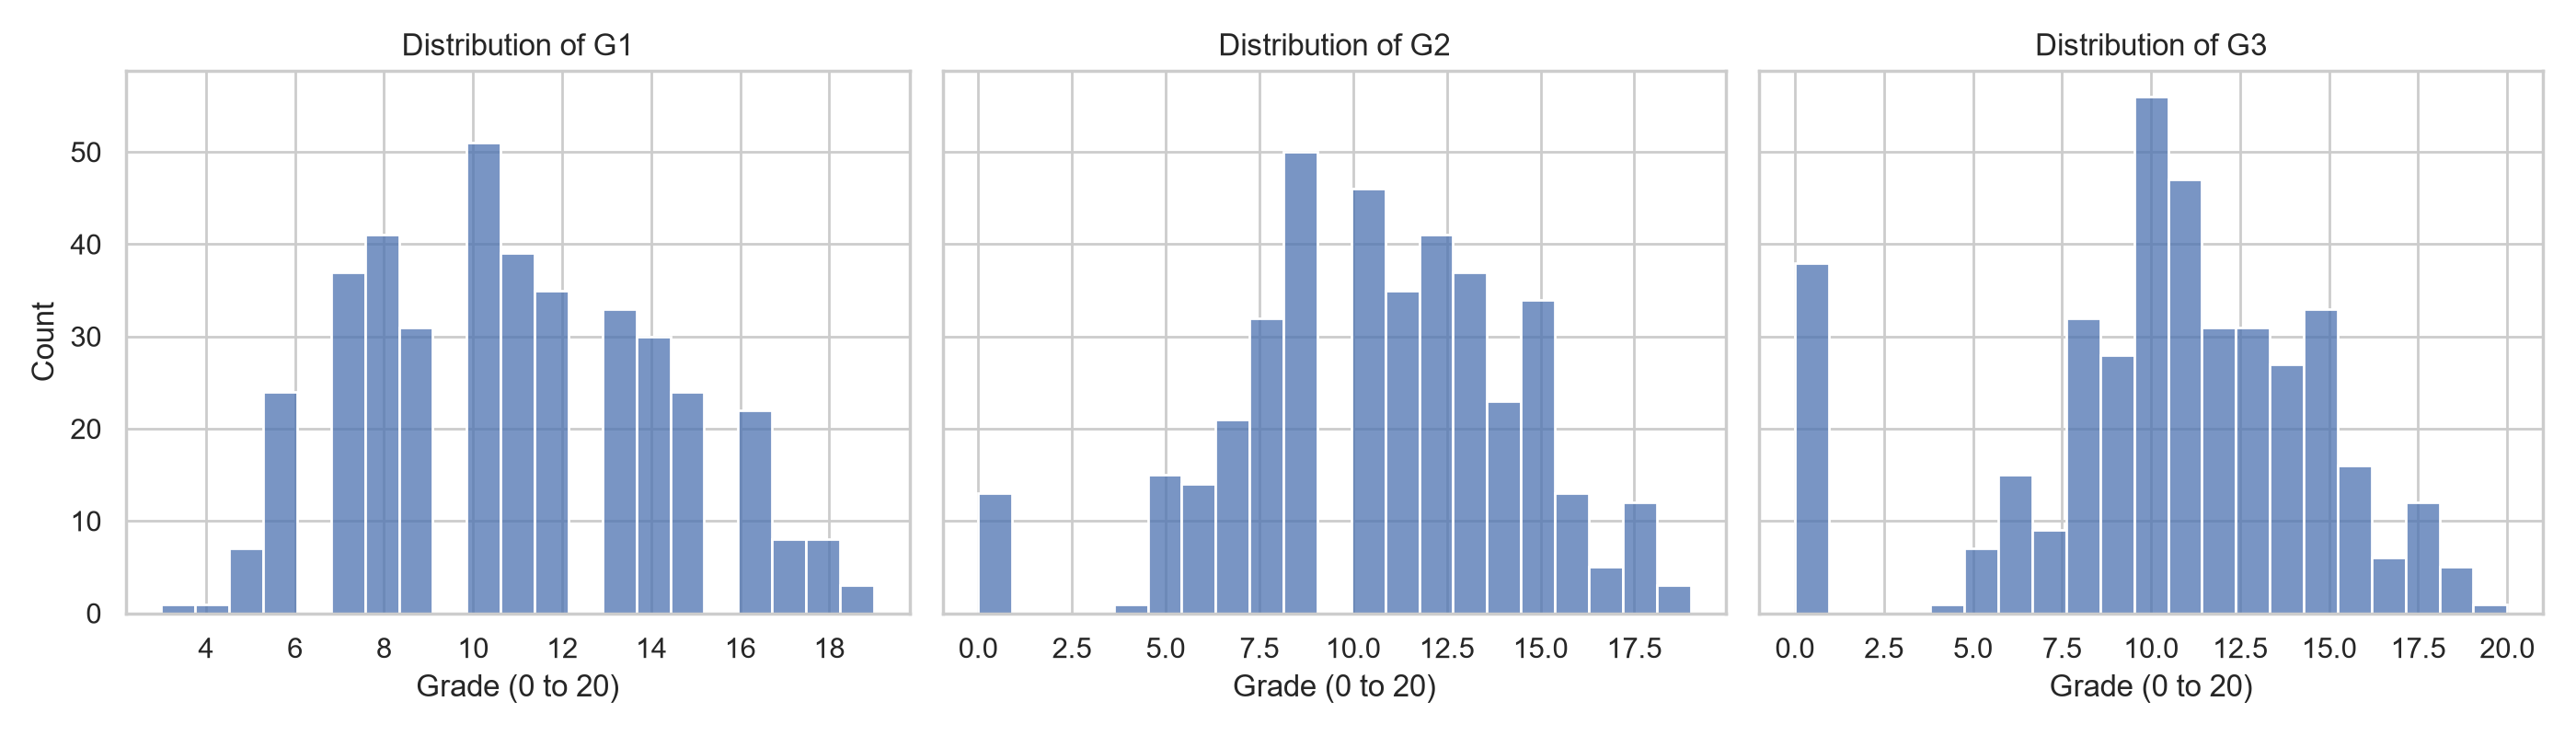

In [4]:
# ===== 1. Data and risk bands =====
mat = pd.read_csv("../data/raw/student-mat.csv", sep=";")
mat["risk"] = mat["G3"].apply(assign_risk)

print("Mathematics file:", mat.shape[0], "students,", mat.shape[1] - 1, "original attributes")

counts = mat["risk"].value_counts().reindex(RISK_ORDER)
summary = pd.DataFrame({"students": counts, "share": (counts / len(mat)).round(3)})
summary["band"] = ["G3 0 to 9", "G3 10 to 13", "G3 14 to 20"]
display(summary)

print("Students with a final grade of zero:", int((mat["G3"] == 0).sum()))
print("Correlation with G3, G1:", round(mat["G1"].corr(mat["G3"]), 3),
      " G2:", round(mat["G2"].corr(mat["G3"]), 3))

show_figure("grade_distributions.png")

Feature set comparison, Random Forest, repeated cross validation


,feature_set,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,"G1, G2 and all others",0.884,0.052,0.876,0.874,0.865
1,"G1 and all others, no G2",0.737,0.076,0.734,0.730,0.719
2,G1 and G2 only,0.885,0.083,0.874,0.872,0.865
3,No grades,0.478,0.072,0.488,0.485,0.488



Top features by permutation importance


,feature,association,measure,mutual_info,permutation_importance
0,romantic,0.113,Cramers V,0.006,0.433
1,internet,0.107,Cramers V,0.006,0.069
2,activities,0.061,Cramers V,0.002,0.005
3,famsup,0.060,Cramers V,0.002,0.004
4,schoolsup,0.175,Cramers V,0.019,0.003
5,Dalc,0.150,abs Spearman,0.027,0.003
6,paid,0.106,Cramers V,0.006,0.002
7,age,0.191,abs Spearman,0.042,0.002
8,G2,0.902,abs Spearman,0.798,0.002
9,studytime,0.109,abs Spearman,0.016,0.002


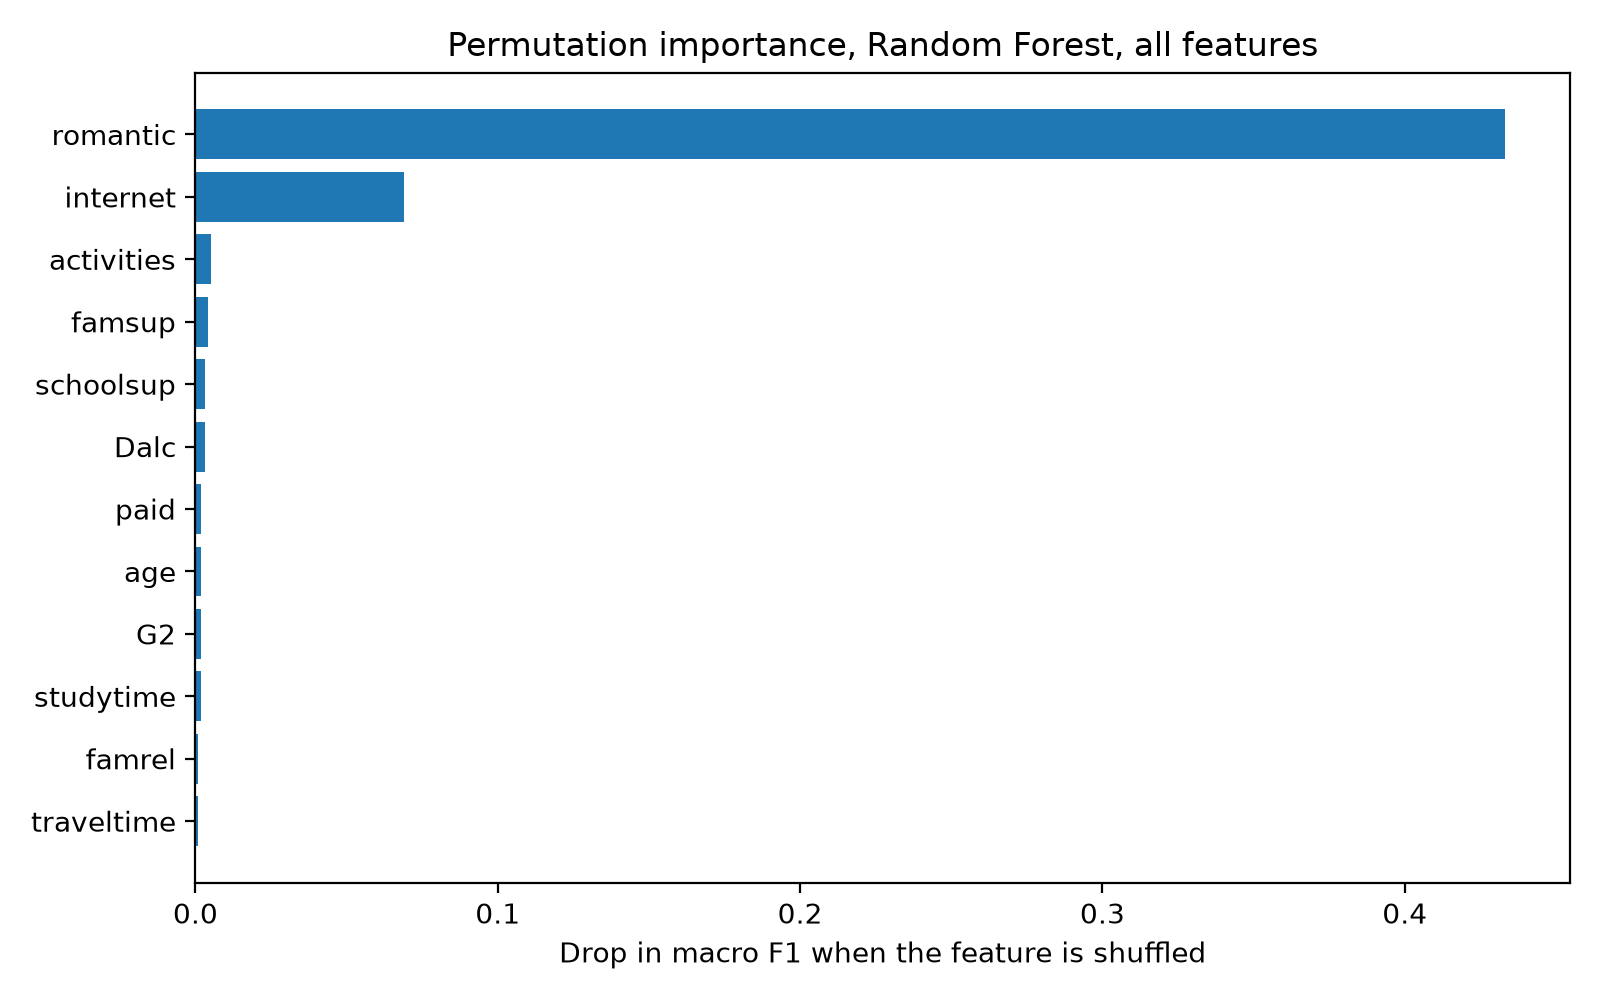

In [5]:
# ===== 2. Feature evidence =====
show_table("cv_feature_sets.csv", "Feature set comparison, Random Forest, repeated cross validation")

evidence = load_table("feature_evidence.csv")
if evidence is not None:
    print("Top features by permutation importance")
    display(evidence.head(10).round(3))

show_figure("permutation_importance.png")

In [6]:
# ===== 3. Simple rules without any learning =====
show_table("baselines.csv", "Rule baselines on the Mathematics file (G2 or G1 carried forward)")

show_table(
    "pooled_stronger_baselines.csv",
    "Stronger simple baselines against logistic regression, average precision for High",
)

Rule baselines on the Mathematics file (G2 or G1 carried forward)


,baseline,recall_high,recall_macro,f1_macro,accuracy
0,G2 carried forward,0.938,0.882,0.884,0.878
1,G1 carried forward,0.800,0.744,0.743,0.734



Stronger simple baselines against logistic regression, average precision for High


,approach,subject,avg_precision,precision_at_90_recall
0,"Rule, G2 only",All,0.877,0.741
1,"Rule, G2 only",Mathematics,0.933,0.845
2,"Rule, G2 only",Portuguese,0.799,0.436
3,Average of G1 and G2,All,0.879,0.672
4,Average of G1 and G2,Mathematics,0.918,0.762
5,Average of G1 and G2,Portuguese,0.834,0.583
6,"Logistic, G2 and subject",All,0.909,0.741
7,"Logistic, G2 and subject",Mathematics,0.943,0.845
8,"Logistic, G2 and subject",Portuguese,0.818,0.564
9,"Logistic, full Stage 2",All,0.920,0.769


,approach,subject,avg_precision,precision_at_90_recall
0,"Rule, G2 only",All,0.877,0.741
1,"Rule, G2 only",Mathematics,0.933,0.845
2,"Rule, G2 only",Portuguese,0.799,0.436
3,Average of G1 and G2,All,0.879,0.672
4,Average of G1 and G2,Mathematics,0.918,0.762
5,Average of G1 and G2,Portuguese,0.834,0.583
6,"Logistic, G2 and subject",All,0.909,0.741
7,"Logistic, G2 and subject",Mathematics,0.943,0.845
8,"Logistic, G2 and subject",Portuguese,0.818,0.564
9,"Logistic, full Stage 2",All,0.920,0.769


Untuned models, Stage 2, average precision for High


subject,Mathematics,Portuguese,mean
model,,,
Logistic regression,0.949,0.872,0.910
Gradient boosting,0.947,0.855,0.901
Random Forest,0.940,0.842,0.891
KNN,0.929,0.833,0.881
Decision Tree,0.908,0.792,0.850


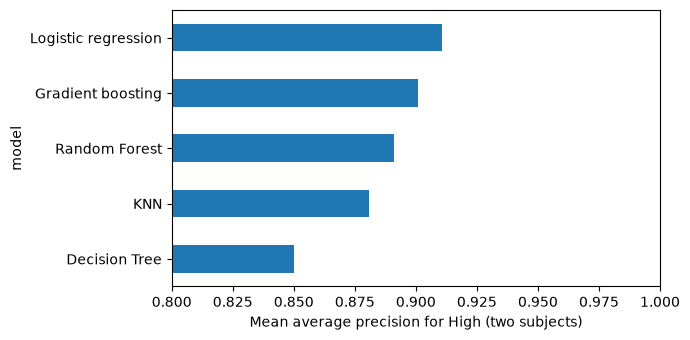

Tuned models, average precision for High


,model,tuning_folds,fresh_folds_all,fresh_folds_math,fresh_folds_port
0,Logistic regression,0.920,0.919,0.944,0.874
1,Random Forest,0.920,0.904,0.939,0.844
2,KNN,0.903,0.899,0.935,0.848
3,Decision Tree,0.891,0.889,0.917,0.843


In [7]:
# ===== 4. Model comparison =====
models_tbl = load_table("pooled_all_models.csv")

if models_tbl is not None:
    stage2 = models_tbl[
        (models_tbl["stage"] == "Stage 2, G1 and G2") & (models_tbl["subject"] != "All")
    ]
    pivot = stage2.pivot_table(index="model", columns="subject", values="avg_precision")
    pivot["mean"] = pivot.mean(axis=1)
    pivot = pivot.sort_values("mean")

    print("Untuned models, Stage 2, average precision for High")
    display(pivot.round(3).iloc[::-1])

    pivot["mean"].plot.barh(figsize=(7, 3.5))
    plt.xlabel("Mean average precision for High (two subjects)")
    plt.xlim(0.8, 1.0)
    plt.tight_layout()
    plt.savefig(FIGURES / "model_comparison_untuned.png", dpi=200)
    plt.show()

# Copied from the tuning and fresh fold outputs in notebook 04
tuned = pd.DataFrame({
    "model": ["Logistic regression", "Random Forest", "KNN", "Decision Tree"],
    "tuning_folds": [0.920, 0.920, 0.903, 0.891],
    "fresh_folds_all": [0.919, 0.904, 0.899, 0.889],
    "fresh_folds_math": [0.944, 0.939, 0.935, 0.917],
    "fresh_folds_port": [0.874, 0.844, 0.848, 0.843],
})
print("Tuned models, average precision for High")
display(tuned)

,approach,subject,n,high_students,recall_high,precision_high,f1_macro,accuracy
0,"Rule, G2 carried forward",All,210,46,0.913,0.667,0.825,0.824
1,"Rule, G2 carried forward",Mathematics,79,26,0.923,0.800,0.869,0.861
2,"Rule, G2 carried forward",Portuguese,131,20,0.900,0.545,0.786,0.802
3,"Random Forest, Stage 2",All,210,46,0.913,0.724,0.829,0.829
4,"Random Forest, Stage 2",Mathematics,79,26,0.923,0.800,0.869,0.861
5,"Random Forest, Stage 2",Portuguese,131,20,0.900,0.643,0.797,0.809
6,"Logistic regression, Stage 2",All,210,46,0.913,0.750,0.808,0.805
7,"Logistic regression, Stage 2",Mathematics,79,26,0.923,0.800,0.855,0.848
8,"Logistic regression, Stage 2",Portuguese,131,20,0.900,0.692,0.778,0.779
9,"Random Forest, Stage 1",All,210,46,0.957,0.571,0.709,0.700


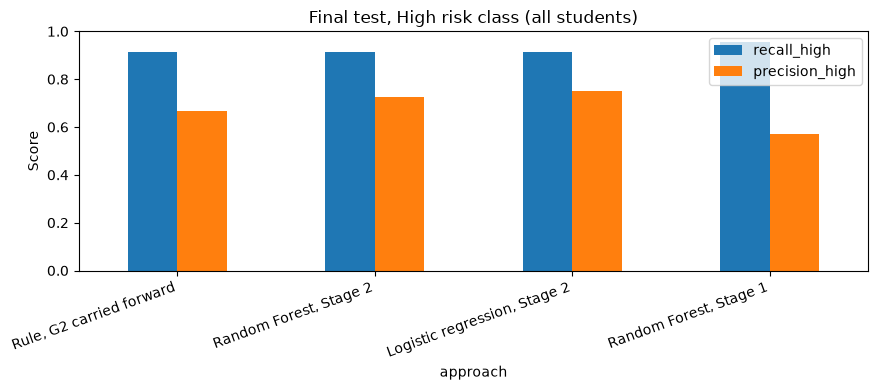

In [8]:
# ===== 5. Final test on students never used for any choice =====
final_tbl = load_table("final_test_results.csv")

if final_tbl is not None:
    display(final_tbl.round(3))

    overall = final_tbl[final_tbl["subject"] == "All"].set_index("approach")
    overall[["recall_high", "precision_high"]].plot.bar(figsize=(9, 4))
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=20, ha="right")
    plt.title("Final test, High risk class (all students)")
    plt.tight_layout()
    plt.savefig(FIGURES / "final_test_summary.png", dpi=200)
    plt.show()

In [9]:
# ===== 6. Frozen Random Forest bundle =====
SUBJECTS = {"mat": 0, "math": 0, "mathematics": 0, "0": 0,
            "por": 1, "portuguese": 1, "1": 1}

STAGE_COLS = {
    "stage1": ["G1", "subject", "G1_x_subject"],
    "stage2": ["G1", "G2", "subject", "G1_x_subject", "G2_x_subject"],
}


def score_students(new_data, bundle):
    data = new_data.copy()

    missing = [c for c in ["subject", "G1"] if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    if "G2" not in data.columns:
        data["G2"] = np.nan

    subject = data["subject"].astype(str).str.strip().str.lower().map(SUBJECTS)
    if subject.isna().any():
        raise ValueError("subject must be Mathematics or Portuguese")
    data["subject"] = subject

    for grade in ["G1", "G2"]:
        data[grade] = pd.to_numeric(data[grade], errors="coerce")
    if data["G1"].isna().any():
        raise ValueError("G1 is required for every student")

    data["G1_x_subject"] = data["G1"] * data["subject"]
    data["G2_x_subject"] = data["G2"] * data["subject"]

    result = pd.DataFrame(index=data.index, columns=["stage", "p_high", "risk"], dtype=object)
    has_g2 = data["G2"].notna()

    for stage, mask in [("stage2", has_g2), ("stage1", ~has_g2)]:
        if not mask.any():
            continue

        model = bundle["models"][stage]
        classes = list(model.classes_)
        proba = model.predict_proba(data.loc[mask, bundle["cols"][stage]])

        p_high = np.round(proba[:, classes.index("High")], 4)
        p_medium = proba[:, classes.index("Medium")]
        p_low = proba[:, classes.index("Low")]

        risk = np.where(p_high >= bundle["thresholds"][stage], "High",
                        np.where(p_medium >= p_low, "Medium", "Low"))

        result.loc[mask, "stage"] = stage
        result.loc[mask, "p_high"] = p_high
        result.loc[mask, "risk"] = risk

    return result


bundle_rf = joblib.load("../models/spark_bundle_rf.joblib")
print("Thresholds in the saved bundle:", {k: round(v, 4) for k, v in bundle_rf["thresholds"].items()})

final = pd.read_csv("../data/processed/final_test_do_not_open.csv")
actual = final["risk"].values

predictions = {
    "Rule, G2 carried forward": final["G2"].apply(assign_risk).values,
    "Random Forest, Stage 2": score_students(final[["subject", "G1", "G2"]], bundle_rf)["risk"].values,
    "Random Forest, Stage 1": score_students(final[["subject", "G1"]], bundle_rf)["risk"].values,
}

for label, pred in predictions.items():
    matrix = pd.DataFrame(
        confusion_matrix(actual, pred, labels=RISK_ORDER),
        index=["true " + r for r in RISK_ORDER],
        columns=["pred " + r for r in RISK_ORDER],
    )
    flagged = int((pred == "High").sum())
    false_alarms = int(((pred == "High") & (actual != "High")).sum())
    missed_to_low = int(((actual == "High") & (pred == "Low")).sum())

    print(label)
    display(matrix)
    print(f"Flagged High: {flagged}, false alarms: {false_alarms}, High predicted as Low: {missed_to_low}\n")

Thresholds in the saved bundle: {'stage1': 0.4855, 'stage2': 0.5043}
Rule, G2 carried forward


,pred High,pred Medium,pred Low
true High,42,4,0
true Medium,21,87,0
true Low,0,12,44


Flagged High: 63, false alarms: 21, High predicted as Low: 0

Random Forest, Stage 2


,pred High,pred Medium,pred Low
true High,42,4,0
true Medium,16,86,6
true Low,0,10,46


Flagged High: 58, false alarms: 16, High predicted as Low: 0

Random Forest, Stage 1


,pred High,pred Medium,pred Low
true High,44,2,0
true Medium,33,58,17
true Low,0,11,45


Flagged High: 77, false alarms: 33, High predicted as Low: 0



In [10]:
# ===== 7. Example students =====
examples = pd.DataFrame({
    "description": [
        "Clearly struggling, Mathematics",
        "Borderline, Mathematics",
        "Same grades, Portuguese",
        "Strong student, Portuguese",
        "Falling grade, Mathematics",
        "Only G1 known, Portuguese",
    ],
    "subject": ["Mathematics", "Mathematics", "Portuguese", "Portuguese", "Mathematics", "Portuguese"],
    "G1": [7, 11, 11, 16, 15, 11],
    "G2": [6, 9, 9, 17, 9, np.nan],
})

scored = score_students(examples[["subject", "G1", "G2"]], bundle_rf)
display(pd.concat([examples, scored], axis=1))

,description,subject,G1,G2,stage,p_high,risk
0,"Clearly struggling, Mathematics",Mathematics,7,6.0,stage2,0.9968,High
1,"Borderline, Mathematics",Mathematics,11,9.0,stage2,0.6744,High
2,"Same grades, Portuguese",Portuguese,11,9.0,stage2,0.2258,Medium
3,"Strong student, Portuguese",Portuguese,16,17.0,stage2,0.0,Low
4,"Falling grade, Mathematics",Mathematics,15,9.0,stage2,0.4665,Medium
5,"Only G1 known, Portuguese",Portuguese,11,NaN,stage1,0.05,Medium


## Summary of version 1

**Task.** Predict the final grade band (High 0 to 9, Medium 10 to 13, Low 14 to 20) from the grades available during the semester.

**What was built.** A frozen Random Forest system with a Stage 2 mode (G1 and G2) and a Stage 1 mode (G1 only), a High threshold set for a target recall of 0.90, and a scoring function that validates new input.

**Main findings.**
- Almost all predictive signal comes from G1 and G2. Other features added no measurable gain.
- On a final test of 210 unseen students, the system caught 42 of 46 High students.
- Stage 1 catches more but flags more students, so an earlier warning costs more false alarms.
- A simple rule (apply the bands to G2) performs almost as well. In Mathematics the system and the rule were identical on the final test. Learning helped mainly for Portuguese students, by reducing false alarms.

**Limitations.** Small test set, secondary school data from two subjects, thresholds chosen on development data, and the Portuguese data informed version 1.

**Questions for the supervisor.** Training on Mathematics only or pooled, framing of the contribution given the baseline result, target recall, and adding logistic regression as a comparison model.